## Activity 1 - Error detection capability

The probability of detecting bit-flip errors is 1 – (probability of not detecting errors) = 1 – p^3

## Activity 2 - Error correction capability

This is the probability of having exactly 0 or 1 bit-flip errors.

So 1 - 3p^2 + 2p^3

## Activity 3 - Efficiency of the method

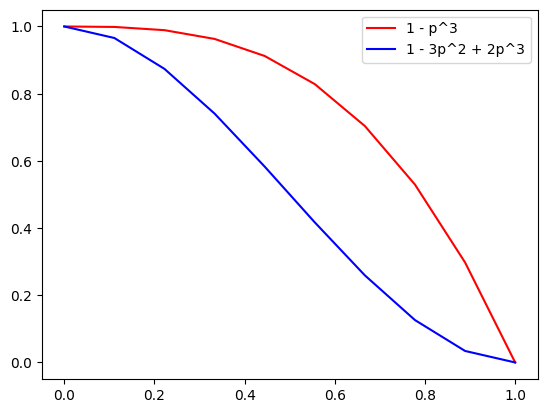

In [94]:
import matplotlib.pyplot as plt
import numpy as np

p = np.linspace(0, 1, 10)
y1 = 1 - p ** 3
y2 = 1 - 3 * p ** 2 + 2 * p ** 3

plt.plot(p, y1, label = "1 - p^3", color='red')
plt.plot(p, y2, label = "1 - 3p^2 + 2p^3", color='blue')
plt.legend()
plt.show()

It's coherent, the curve of the probability of being able to correct the error must be under the probability of error detection. We can't correct if we don't detect any error.

## Activity 4 - No-cloning theorem

On a quantum computer, qubits state cannot be copied without destructing the original state.

## Activity 5 - Entangling qubits

In [67]:
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit.quantum_info import Statevector, Operator
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram
from qiskit.visualization import plot_bloch_vector
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

from math import sqrt, pi
import random

     ┌───┐          ┌─┐      
q_0: ┤ H ├──■───────┤M├──────
     └───┘┌─┴─┐     └╥┘┌─┐   
q_1: ─────┤ X ├──■───╫─┤M├───
          └───┘┌─┴─┐ ║ └╥┘┌─┐
q_2: ──────────┤ X ├─╫──╫─┤M├
               └───┘ ║  ║ └╥┘
c: 3/════════════════╩══╩══╩═
                     2  1  0 
{'000': 521, '111': 503}


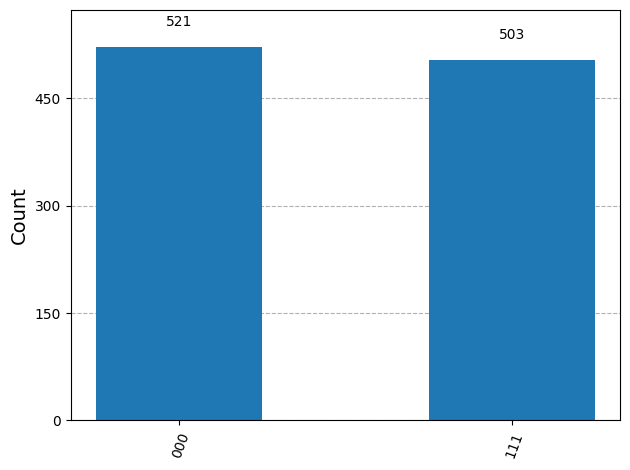

In [18]:
qc = QuantumCircuit(3, 3)

qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.measure([0, 1, 2], [2, 1, 0])

print(qc)

job = StatevectorSampler().run([qc], shots=1024)
result = job.result()

data = result[0].data
counts = data.c.get_counts()

print(counts)
plot_histogram(counts)

We start from the state (1/sqrt(2))|0> + (1/sqrt(2))|1> and we finally find the state (1/sqrt(2))|000> + (1/sqrt(2))|111>, which is what we want.

## Activity 6 - Adding bit-flip noise

     ┌───┐           ░       ░ ┌─┐      
q_0: ┤ H ├──■────────░───────░─┤M├──────
     └───┘┌─┴─┐      ░ ┌───┐ ░ └╥┘┌─┐   
q_1: ─────┤ X ├──■───░─┤ X ├─░──╫─┤M├───
          └───┘┌─┴─┐ ░ └───┘ ░  ║ └╥┘┌─┐
q_2: ──────────┤ X ├─░───────░──╫──╫─┤M├
               └───┘ ░       ░  ║  ║ └╥┘
c: 3/═══════════════════════════╩══╩══╩═
                                2  1  0 
{'101': 520, '010': 504}


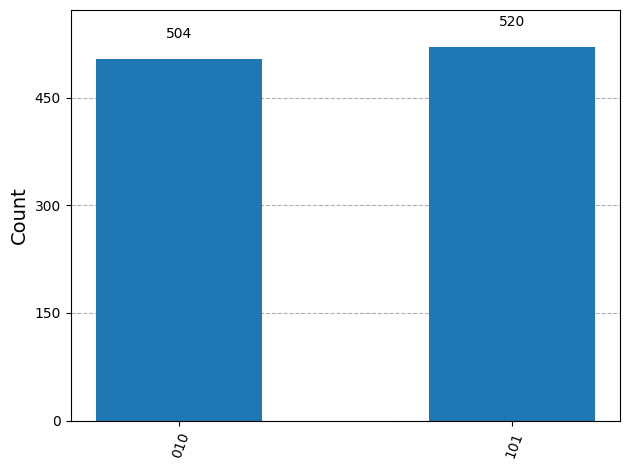

In [38]:
qc = QuantumCircuit(3, 3)

qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.barrier()
qc.x(1)
qc.barrier()
qc.measure([0, 1, 2], [2, 1, 0])

print(qc)

job = StatevectorSampler().run([qc], shots=1024)
result = job.result()

data = result[0].data
counts = data.c.get_counts()

print(counts)
plot_histogram(counts)

By adding a bit flip error on the 2nd qubit, we expect to get the state a|010> + b|101> (with a = b = 1/sqrt(2)). And the result from the simulation gives us exactly what we expected.

     ┌───┐           ░ ┌───┐ ░ ┌─┐      
q_0: ┤ H ├──■────────░─┤ X ├─░─┤M├──────
     └───┘┌─┴─┐      ░ ├───┤ ░ └╥┘┌─┐   
q_1: ─────┤ X ├──■───░─┤ X ├─░──╫─┤M├───
          └───┘┌─┴─┐ ░ ├───┤ ░  ║ └╥┘┌─┐
q_2: ──────────┤ X ├─░─┤ X ├─░──╫──╫─┤M├
               └───┘ ░ └───┘ ░  ║  ║ └╥┘
c: 3/═══════════════════════════╩══╩══╩═
                                2  1  0 
{'000': 515, '111': 509}


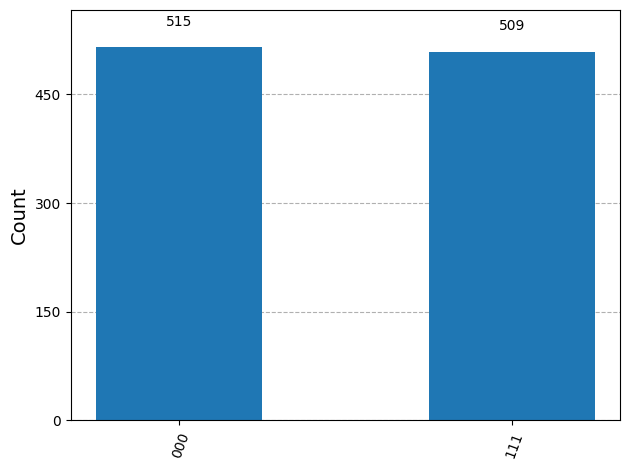

In [37]:
qc = QuantumCircuit(3, 3)

qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.barrier()
qc.x(0)
qc.x(1)
qc.x(2)
qc.barrier()
qc.measure([0, 1, 2], [2, 1, 0])

print(qc)

job = StatevectorSampler().run([qc], shots=1024)
result = job.result()

data = result[0].data
counts = data.c.get_counts()

print(counts)
plot_histogram(counts)

By adding bit-flip errors on each qubit, we expect to get the state a|000> + b|111> and that is exactly the result of the simulation. We can see that we cannot identify any error.

## Activity 7 - Syndrome measurement

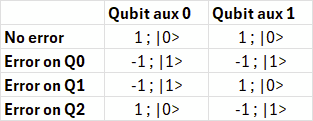

By measuring the Z observable we either get 1 or -1 as syndrome.

In [54]:
qc = QuantumCircuit(5, 5)

qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.barrier()
# qc.x(0)
# qc.x(1)
# qc.x(2)
qc.barrier()
qc.cx(0, 3)
qc.cx(1, 3)
qc.cx(0, 4)
qc.cx(2, 4)
qc.barrier()
qc.measure([3, 4], [4, 3])

print(qc)

job = StatevectorSampler().run([qc], shots=1024)
result = job.result()

data = result[0].data
counts = data.c.get_counts()

print(counts)
# plot_histogram(counts)

     ┌───┐           ░  ░                      ░       
q_0: ┤ H ├──■────────░──░───■─────────■────────░───────
     └───┘┌─┴─┐      ░  ░   │         │        ░       
q_1: ─────┤ X ├──■───░──░───┼────■────┼────────░───────
          └───┘┌─┴─┐ ░  ░   │    │    │        ░       
q_2: ──────────┤ X ├─░──░───┼────┼────┼────■───░───────
               └───┘ ░  ░ ┌─┴─┐┌─┴─┐  │    │   ░ ┌─┐   
q_3: ────────────────░──░─┤ X ├┤ X ├──┼────┼───░─┤M├───
                     ░  ░ └───┘└───┘┌─┴─┐┌─┴─┐ ░ └╥┘┌─┐
q_4: ────────────────░──░───────────┤ X ├┤ X ├─░──╫─┤M├
                     ░  ░           └───┘└───┘ ░  ║ └╥┘
c: 5/═════════════════════════════════════════════╩══╩═
                                                  4  3 
{'00000': 1024}


=> No errors : we get the **state |00>** as expected in the theoretical prediction

In [53]:
qc = QuantumCircuit(5, 5)

qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.barrier()
qc.x(0)
# qc.x(1)
# qc.x(2)
qc.barrier()
qc.cx(0, 3)
qc.cx(1, 3)
qc.cx(0, 4)
qc.cx(2, 4)
qc.barrier()
qc.measure([3, 4], [4, 3])

print(qc)

job = StatevectorSampler().run([qc], shots=1024)
result = job.result()

data = result[0].data
counts = data.c.get_counts()

print(counts)
# plot_histogram(counts)

     ┌───┐           ░ ┌───┐ ░                      ░       
q_0: ┤ H ├──■────────░─┤ X ├─░───■─────────■────────░───────
     └───┘┌─┴─┐      ░ └───┘ ░   │         │        ░       
q_1: ─────┤ X ├──■───░───────░───┼────■────┼────────░───────
          └───┘┌─┴─┐ ░       ░   │    │    │        ░       
q_2: ──────────┤ X ├─░───────░───┼────┼────┼────■───░───────
               └───┘ ░       ░ ┌─┴─┐┌─┴─┐  │    │   ░ ┌─┐   
q_3: ────────────────░───────░─┤ X ├┤ X ├──┼────┼───░─┤M├───
                     ░       ░ └───┘└───┘┌─┴─┐┌─┴─┐ ░ └╥┘┌─┐
q_4: ────────────────░───────░───────────┤ X ├┤ X ├─░──╫─┤M├
                     ░       ░           └───┘└───┘ ░  ║ └╥┘
c: 5/══════════════════════════════════════════════════╩══╩═
                                                       4  3 
{'11000': 1024}


=> Error on qubit 0 : we measure the **state |11>** for the ancillas.

In [52]:
qc = QuantumCircuit(5, 5)

qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.barrier()
# qc.x(0)
qc.x(1)
# qc.x(2)
qc.barrier()
qc.cx(0, 3)
qc.cx(1, 3)
qc.cx(0, 4)
qc.cx(2, 4)
qc.barrier()
qc.measure([3, 4], [4, 3])

print(qc)

job = StatevectorSampler().run([qc], shots=1024)
result = job.result()

data = result[0].data
counts = data.c.get_counts()

print(counts)
# plot_histogram(counts)

     ┌───┐           ░       ░                      ░       
q_0: ┤ H ├──■────────░───────░───■─────────■────────░───────
     └───┘┌─┴─┐      ░ ┌───┐ ░   │         │        ░       
q_1: ─────┤ X ├──■───░─┤ X ├─░───┼────■────┼────────░───────
          └───┘┌─┴─┐ ░ └───┘ ░   │    │    │        ░       
q_2: ──────────┤ X ├─░───────░───┼────┼────┼────■───░───────
               └───┘ ░       ░ ┌─┴─┐┌─┴─┐  │    │   ░ ┌─┐   
q_3: ────────────────░───────░─┤ X ├┤ X ├──┼────┼───░─┤M├───
                     ░       ░ └───┘└───┘┌─┴─┐┌─┴─┐ ░ └╥┘┌─┐
q_4: ────────────────░───────░───────────┤ X ├┤ X ├─░──╫─┤M├
                     ░       ░           └───┘└───┘ ░  ║ └╥┘
c: 5/══════════════════════════════════════════════════╩══╩═
                                                       4  3 
{'10000': 1024}


=> Error on qubit 1 : we get the **state |10>** as expected in the theory

     ┌───┐           ░       ░                      ░       
q_0: ┤ H ├──■────────░───────░───■─────────■────────░───────
     └───┘┌─┴─┐      ░       ░   │         │        ░       
q_1: ─────┤ X ├──■───░───────░───┼────■────┼────────░───────
          └───┘┌─┴─┐ ░ ┌───┐ ░   │    │    │        ░       
q_2: ──────────┤ X ├─░─┤ X ├─░───┼────┼────┼────■───░───────
               └───┘ ░ └───┘ ░ ┌─┴─┐┌─┴─┐  │    │   ░ ┌─┐   
q_3: ────────────────░───────░─┤ X ├┤ X ├──┼────┼───░─┤M├───
                     ░       ░ └───┘└───┘┌─┴─┐┌─┴─┐ ░ └╥┘┌─┐
q_4: ────────────────░───────░───────────┤ X ├┤ X ├─░──╫─┤M├
                     ░       ░           └───┘└───┘ ░  ║ └╥┘
c: 5/══════════════════════════════════════════════════╩══╩═
                                                       4  3 
{'01000': 1024}


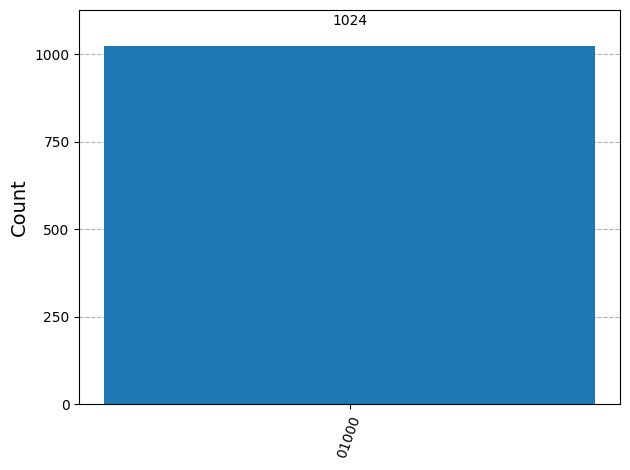

In [51]:
qc = QuantumCircuit(5, 5)

qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.barrier()
# qc.x(0)
# qc.x(1)
qc.x(2)
qc.barrier()
qc.cx(0, 3)
qc.cx(1, 3)
qc.cx(0, 4)
qc.cx(2, 4)
qc.barrier()
qc.measure([3, 4], [4, 3])

print(qc)

job = StatevectorSampler().run([qc], shots=1024)
result = job.result()

data = result[0].data
counts = data.c.get_counts()

print(counts)
# plot_histogram(counts)

=> Error on qubit 2 : we measure the **state |01>** as expected in the theoretical prediction

## Activity 8 - Correcting errors

* |00> = no errors detected = nothing to correct
* |11> = bit-flip error detected on the qubit 0 = apply X on the qubit 0 to correct it
* |10> = bit-flip error detected on the qubit 1 = apply X on the qubit 1 to correct it
* |10> = bit-flip error detected on the qubit 2 = apply X on the qubit 2 to correct it

## Activity 9 - Final test

In [123]:
qc = QuantumCircuit(5, 2)

# sv=Statevector([1/sqrt(2), -1/sqrt(2)])
sv=Statevector([sqrt(2/3), sqrt(1/3)])
qc.initialize(sv, 0)

# qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.barrier()
# qc.x(0)
qc.x(1)
# qc.x(2)
qc.barrier()
qc.cx(0, 3)
qc.cx(1, 3)
qc.cx(0, 4)
qc.cx(2, 4)
qc.barrier()
qc.measure([3, 4], [1, 0])
qc.barrier()

job = StatevectorSampler().run([qc], shots=1)
result = job.result()
data = result[0].data
syndrome = data.c.get_bitstrings()[0]
print(syndrome)

if (syndrome == "11"): # Error on qubit 0
  qc.x(0)
if (syndrome == "10"): # Error on qubit 1
  qc.x(1)
if (syndrome == "01"): # Error on qubit 2
  qc.x(2)

print(qc)


# with qc.if_test((qc.clbits[0], 1)) and qc.if_test((qc.clbits[1], 1)):
#     qc.x(0)

# with qc.if_test((qc.clbits[0], 1)) and qc.if_test((qc.clbits[1], 0)):
#     qc.x(1)

# with qc.if_test((qc.clbits[0], 0)) and qc.if_test((qc.clbits[1], 1)):
#     qc.x(2)


10
     ┌────────────────────────────┐           ░       ░                      ░ »
q_0: ┤ Initialize(0.8165,0.57735) ├──■────────░───────░───■─────────■────────░─»
     └────────────────────────────┘┌─┴─┐      ░ ┌───┐ ░   │         │        ░ »
q_1: ──────────────────────────────┤ X ├──■───░─┤ X ├─░───┼────■────┼────────░─»
                                   └───┘┌─┴─┐ ░ └───┘ ░   │    │    │        ░ »
q_2: ───────────────────────────────────┤ X ├─░───────░───┼────┼────┼────■───░─»
                                        └───┘ ░       ░ ┌─┴─┐┌─┴─┐  │    │   ░ »
q_3: ─────────────────────────────────────────░───────░─┤ X ├┤ X ├──┼────┼───░─»
                                              ░       ░ └───┘└───┘┌─┴─┐┌─┴─┐ ░ »
q_4: ─────────────────────────────────────────░───────░───────────┤ X ├┤ X ├─░─»
                                              ░       ░           └───┘└───┘ ░ »
c: 2/══════════════════════════════════════════════════════════════════════════»
                         

## Activity 10 - The case of two simultaneous bit-flip errors

In [124]:
qc = QuantumCircuit(5, 2)

sv=Statevector([sqrt(2/3), sqrt(1/3)])
qc.initialize(sv, 0)

qc.cx(0, 1)
qc.cx(1, 2)
qc.barrier()
### ERRORS ###
qc.x(0)
# qc.x(1)
qc.x(2)
##############
qc.barrier()
qc.cx(0, 3)
qc.cx(1, 3)
qc.cx(0, 4)
qc.cx(2, 4)
qc.barrier()
qc.measure([3, 4], [1, 0])
qc.barrier()

job = StatevectorSampler().run([qc], shots=1)
result = job.result()
data = result[0].data
syndrome = data.c.get_bitstrings()[0]
print(syndrome)

if (syndrome == "11"): # Error on qubit 0
  qc.x(0)
if (syndrome == "10"): # Error on qubit 1
  qc.x(1)
if (syndrome == "01"): # Error on qubit 2
  qc.x(2)

print(qc)



10
     ┌────────────────────────────┐           ░ ┌───┐ ░                      ░ »
q_0: ┤ Initialize(0.8165,0.57735) ├──■────────░─┤ X ├─░───■─────────■────────░─»
     └────────────────────────────┘┌─┴─┐      ░ └───┘ ░   │         │        ░ »
q_1: ──────────────────────────────┤ X ├──■───░───────░───┼────■────┼────────░─»
                                   └───┘┌─┴─┐ ░ ┌───┐ ░   │    │    │        ░ »
q_2: ───────────────────────────────────┤ X ├─░─┤ X ├─░───┼────┼────┼────■───░─»
                                        └───┘ ░ └───┘ ░ ┌─┴─┐┌─┴─┐  │    │   ░ »
q_3: ─────────────────────────────────────────░───────░─┤ X ├┤ X ├──┼────┼───░─»
                                              ░       ░ └───┘└───┘┌─┴─┐┌─┴─┐ ░ »
q_4: ─────────────────────────────────────────░───────░───────────┤ X ├┤ X ├─░─»
                                              ░       ░           └───┘└───┘ ░ »
c: 2/══════════════════════════════════════════════════════════════════════════»
                         

The 3-qubit bit-flip code works with majority-vote so by applying 2 errors, the code won't detect the 2 errors but the other qubit that hasn't been flipped and it will change it.

For example, an bit-flip on qubit 0 and a bit-flip on qubit 2 will result in the syndrome |10> which is the syndrome of a bit-flip on qubit 1 (as expected by theoretical prediction)

At the end of the circuit, all the qubits will be flipped.

## Activity 11 - The case of a phase-flip error

In [143]:
qc = QuantumCircuit(5, 2)

sv=Statevector([sqrt(2/3), sqrt(1/3)])
qc.initialize(sv, 0)

qc.cx(0, 1)
qc.cx(1, 2)
qc.barrier()
### ERRORS ###
# qc.z(0)
qc.z(1)
# qc.x(2)
##############
qc.barrier()
qc.cx(0, 3)
qc.cx(1, 3)
qc.cx(0, 4)
qc.cx(2, 4)
qc.barrier()
qc.measure([3, 4], [1, 0])
qc.barrier()

job = StatevectorSampler().run([qc], shots=1)
result = job.result()
data = result[0].data
syndrome = data.c.get_bitstrings()[0]
print("Syndrome :", syndrome)

if (syndrome == "11"): # Bit-flip error on qubit 0
  qc.x(0)
if (syndrome == "10"): # Bit-flip error on qubit 1
  qc.x(1)
if (syndrome == "01"): # Bit-flip error on qubit 2
  qc.x(2)

print(qc)
print("PROBLEM !")



Syndrome : 00
     ┌────────────────────────────┐           ░       ░                      ░ »
q_0: ┤ Initialize(0.8165,0.57735) ├──■────────░───────░───■─────────■────────░─»
     └────────────────────────────┘┌─┴─┐      ░ ┌───┐ ░   │         │        ░ »
q_1: ──────────────────────────────┤ X ├──■───░─┤ Z ├─░───┼────■────┼────────░─»
                                   └───┘┌─┴─┐ ░ └───┘ ░   │    │    │        ░ »
q_2: ───────────────────────────────────┤ X ├─░───────░───┼────┼────┼────■───░─»
                                        └───┘ ░       ░ ┌─┴─┐┌─┴─┐  │    │   ░ »
q_3: ─────────────────────────────────────────░───────░─┤ X ├┤ X ├──┼────┼───░─»
                                              ░       ░ └───┘└───┘┌─┴─┐┌─┴─┐ ░ »
q_4: ─────────────────────────────────────────░───────░───────────┤ X ├┤ X ├─░─»
                                              ░       ░           └───┘└───┘ ░ »
c: 2/══════════════════════════════════════════════════════════════════════════»
              

Our current code will never detect any phase-flip error because the syndrome is always |00>.

We need to change the basis of the CNOT to detect phase-flip errors.

H|+> = |0> but H|-> = |1> (this enable the CNOT to be activated when a phase-flip is detected)

In [144]:
qc = QuantumCircuit(5, 2)

qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.barrier()
qc.h([0, 1, 2])
### ERRORS ###
# qc.z(0)
qc.z(1)
# qc.z(2)
##############
qc.barrier()
qc.h([0, 1, 2])
qc.cx(0, 3)
qc.cx(1, 3)
qc.cx(0, 4)
qc.cx(2, 4)
qc.h([0, 1, 2])
qc.barrier()
qc.measure([3, 4], [1, 0])
qc.barrier()

job = StatevectorSampler().run([qc], shots=1)
result = job.result()
data = result[0].data
syndrome = data.c.get_bitstrings()[0]
print("Syndrome :", syndrome)

if (syndrome == "11"): # Phase-flip error on qubit 0
  qc.z(0)
if (syndrome == "10"): # Phase-flip error on qubit 1
  qc.z(1)
if (syndrome == "01"): # Phase-flip error on qubit 2
  qc.z(2)

print(qc)



Syndrome : 10
     ┌───┐           ░ ┌───┐      ░ ┌───┐               ┌───┐      ░        ░ »
q_0: ┤ H ├──■────────░─┤ H ├──────░─┤ H ├──■─────────■──┤ H ├──────░────────░─»
     └───┘┌─┴─┐      ░ ├───┤┌───┐ ░ ├───┤  │         │  ├───┤      ░        ░ »
q_1: ─────┤ X ├──■───░─┤ H ├┤ Z ├─░─┤ H ├──┼────■────┼──┤ H ├──────░────────░─»
          └───┘┌─┴─┐ ░ ├───┤└───┘ ░ ├───┤  │    │    │  └───┘┌───┐ ░        ░ »
q_2: ──────────┤ X ├─░─┤ H ├──────░─┤ H ├──┼────┼────┼────■──┤ H ├─░────────░─»
               └───┘ ░ └───┘      ░ └───┘┌─┴─┐┌─┴─┐  │    │  └───┘ ░ ┌─┐    ░ »
q_3: ────────────────░────────────░──────┤ X ├┤ X ├──┼────┼────────░─┤M├────░─»
                     ░            ░      └───┘└───┘┌─┴─┐┌─┴─┐      ░ └╥┘┌─┐ ░ »
q_4: ────────────────░────────────░────────────────┤ X ├┤ X ├──────░──╫─┤M├─░─»
                     ░            ░                └───┘└───┘      ░  ║ └╥┘ ░ »
c: 2/═════════════════════════════════════════════════════════════════╩══╩════»
                          

The encoded state is a|+++> + b|---> so the logical encoded state is a|+> + b|->

## Activity 12 - Logical basis states

If |psi> = |0>, the first 2 CNOTs gives us the state |000>, the the H gates gives (1/sqrt(2)(|0>+|1>))*3 and the next CNOTs completes to ((1/sqrt(2))(|000>+|111>))*3

In the same way, if |psi> = |1>   --->   |111>    ---> (1/sqrt(2)(|0>-|1>))*3   --->   ((1/sqrt(2))(|000>-|111>))*3

To verify that |0⟩L and |1⟩L are orthogonal states, we need to calculate <0L|1L>

<0L|1L> = (a(<000| + <111|))*3 * (a(|000> - |111>))*3  ( with a = 1 / sqrt(2) )

and (<000| + <111|)(|000> - |111>) = <000|000> - <000|111> + <111|000> - <111|111> = 1 - 0 + 0 - 1 = 0

So <0L|1L> = 0, so |0L> and |1L> are orthogonal.


|+>L = 1/sqrt(2) |0>L + |1>L

So by developing |0>L and |1>L with A = |000> and B = |111>,

|0>L = 1/2^(3/2) ( AAA + AAB + ABA + ABB + BAA + BAB + BBA + BBB )

|1>L = 1/2^(3/2) ( AAA - AAB - ABA + ABB - BAA + BAB + BBA - BBB )

Donc |+>L = 1/2 ( AAA + ABB + BAB + BBA ) = 1/2 ( |000000000> + |000111111> + |111000111> + |111111000> )

In [158]:
qc = QuantumCircuit(9, 9)

# qc.h(0)
# qc.x(0)
qc.barrier()

qc.cx(0, 3)
qc.cx(0, 6)
qc.barrier()

qc.h([0, 3, 6])

qc.cx(0, 1)
qc.cx(0, 2)

qc.cx(3, 4)
qc.cx(3, 5)

qc.cx(6, 7)
qc.cx(6, 8)

qc.measure_all()

print(qc)

job = StatevectorSampler().run([qc], shots=1024)
result = job.result()

data = result[0].data
counts = data.c.get_counts()

print(counts)
# plot_histogram(counts)

         ░            ░ ┌───┐           ░ ┌─┐                        
   q_0: ─░───■────■───░─┤ H ├──■────■───░─┤M├────────────────────────
         ░   │    │   ░ └───┘┌─┴─┐  │   ░ └╥┘┌─┐                     
   q_1: ─░───┼────┼───░──────┤ X ├──┼───░──╫─┤M├─────────────────────
         ░   │    │   ░      └───┘┌─┴─┐ ░  ║ └╥┘┌─┐                  
   q_2: ─░───┼────┼───░───────────┤ X ├─░──╫──╫─┤M├──────────────────
         ░ ┌─┴─┐  │   ░ ┌───┐     └───┘ ░  ║  ║ └╥┘┌─┐               
   q_3: ─░─┤ X ├──┼───░─┤ H ├──■────■───░──╫──╫──╫─┤M├───────────────
         ░ └───┘  │   ░ └───┘┌─┴─┐  │   ░  ║  ║  ║ └╥┘┌─┐            
   q_4: ─░────────┼───░──────┤ X ├──┼───░──╫──╫──╫──╫─┤M├────────────
         ░        │   ░      └───┘┌─┴─┐ ░  ║  ║  ║  ║ └╥┘┌─┐         
   q_5: ─░────────┼───░───────────┤ X ├─░──╫──╫──╫──╫──╫─┤M├─────────
         ░      ┌─┴─┐ ░ ┌───┐     └───┘ ░  ║  ║  ║  ║  ║ └╥┘┌─┐      
   q_6: ─░──────┤ X ├─░─┤ H ├──■────■───░──╫──╫──╫──╫──╫──╫─┤M├──────
         ░      └───

## Activity 13 - Correcting arbitrary single-qubit errors

The Shor code can correct X errors and Z errors independently. And Y errors are just simultaneous X error and Z errors. (in fact Y = iXZ)



Any quantum single-qubit error is a combination of X, Z, and Y (and I) gates so a combination of X, Z, and Y errors, so the Shor code can correct any single-qubit error step by step.

## Activity 14 - Error syndrome

For each 3 blocks of qubits, we need 2 bits to encode the bit-flip syndrome. So it's 2 * 3 = 6 bits in total to precisely detect bit-flips. And to perform a phase-flip correction, we need 2 bits.

So in total, the Shor code encoded the full syndrome on 8 bits.